# Heuers' statistical Football model

The following implementation aims to recreate the Football model of Prof. Dr. Andreas Heuer.

In [65]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
SEED = 1893

In [66]:
# Helperfunctions
def plot_per_season_per_country(df, y, fit_reg=True):
    seasons = [14, 15, 16, 17, 18]
    sns.lmplot(x="season", y=y,
               hue="country", data=df, ci=None, fit_reg=fit_reg)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    sumed_df = pd.DataFrame()
    sumed_df["season"] = seasons
    total = []
    for season in seasons:
        total.append(np.sum(df.groupby(["season"]).get_group(
            season)[y]) / NUM_OF_COUNTRIES)
    sumed_df[y] = total
    sns.lmplot(x="season", y=y,
               data=sumed_df, ci=None, fit_reg=fit_reg)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    plt.show()

def closed_form_solution(X, y):
    # alternative: np.dot(np.linalg.inv(np.dot(X.T, X)), np.dot(X.T, y))
    return np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))


## Step 1 - Homefieldadvantage (per country and season)

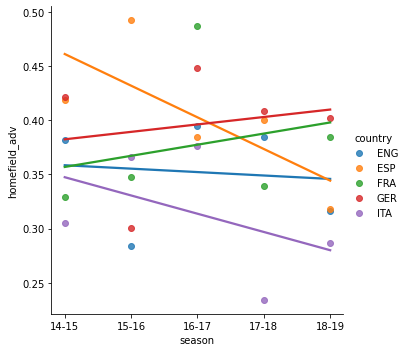

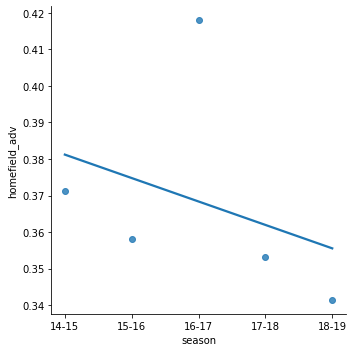

In [67]:
df_homefield = pd.read_csv('data/homefield_adv.csv', sep=';')
plot_per_season_per_country(df_homefield, y="homefield_adv")

Homefield advantage tends to have high variance, a clear trend per country or season is not visible.
Therefor homefield advantage will be modeled as an constant of the average of hometeamgoals - awayteamgoals

In [68]:
avg_homefield_adv = np.sum(df_homefield["homefield_adv"]) / NUM_OF_SEASONS
print("Average homefield advantage on all games:")
avg_homefield_adv

Average homefield advantage on all games:


0.36837358101135187

In [69]:

df_country_season_homefield_adv = pd.read_csv(
    "data/country_season_homefield_adv.csv", sep=";")
# df_country_season_homefield_adv['bias'] = 1


def h_country_season_homefield_adv(country, season, matchnumber):
    sub_df = df_country_season_homefield_adv.query(
        f"country == '{country}' and season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["hf_adv_last_three_seasons",
                "hf_adv_current_season"]].values  # no bias
    y = sub_df["hf_adv_actual"].values

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_country_season_homefield_adv.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["hf_adv_last_three_seasons",
                      "hf_adv_current_season"]].values  # no bias

    return np.dot(w, input.T)[0]


print("Homefield advantage:", h_country_season_homefield_adv("GER", 17, 11))


Homefield advantage: 0.2989268635429185


## Step 2 - Goalamount per match (per country and season)

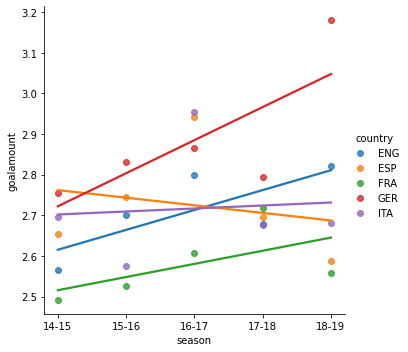

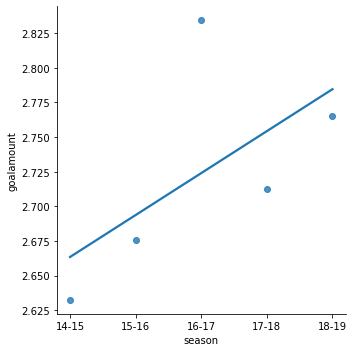

In [70]:
df_goalamount = pd.read_csv('data/goalamount.csv', sep=';')
plot_per_season_per_country(df_goalamount, "goalamount")

there are higher scored countrys as well as lower scoring ones
for now the goalamount will be modeled as a constant

In [71]:
avg_goalamount = np.sum(df_goalamount["goalamount"]) / NUM_OF_SEASONS
print("Average goalamount of all games:")
avg_goalamount

Average goalamount of all games:


2.724046095631235

In [72]:
df_country_season_goalamount = pd.read_csv(
    "data/country_season_goalamount.csv", sep=";")
# df_country_season_goalamount['bias'] = 1


def h_country_season_goalamount(country, season, matchnumber):
    sub_df = df_country_season_goalamount.query(
        f"country == '{country}' and season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["ga_last_three_seasons",
                "ga_current_season"]].values  # no bias
    y = sub_df["ga_actual"].values

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_country_season_goalamount.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["ga_last_three_seasons",
                      "ga_current_season"]].values  # no bias
    return np.dot(w, input.T)[0]


print("Goalamount:", h_country_season_goalamount("GER", 18, 34))

Goalamount: 3.208489297178785


## Step 3: Teamstrength and expected goaldifference

In the first season (14/15) every team is treated promoter.

In [73]:
df_teamstrength = pd.read_csv('data/teamstrength.csv', sep=';')
df_teamstrength

,country,season,matchnumber,teamname,curr_chancediff,past_chancediff1,past_chancediff2,past_chancediff3,marketvalue,actual_goaldiff,past_chancediff_combined,market_value_ln_relative,past_chanceamount,actual_goalamount
0,ENG,14,1,Queens Park Rangers,0.000000,0.000000,0.000000,0.000000,112,-1,0.000000,-0.392415,0.000000,1
1,ENG,14,1,Hull,0.000000,0.000000,0.000000,0.000000,117,1,0.000000,-0.348740,0.000000,1
2,ENG,14,1,Newcastle,0.000000,0.000000,0.000000,0.000000,140,-2,0.000000,-0.169272,0.000000,2
3,ENG,14,1,Man City,0.000000,0.000000,0.000000,0.000000,452,2,0.000000,1.002768,0.000000,2
4,ENG,14,1,Burnley,0.000000,0.000000,0.000000,0.000000,53,-2,0.000000,-1.140622,0.000000,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18255,ITA,18,38,Napoli,3.526316,5.447368,5.052632,5.342105,647,-1,5.293421,1.070083,337.333333,5
18256,ITA,18,38,Inter,2.210526,3.210526,1.921053,0.684211,618,1,2.380263,1.024225,256.666667,3
18257,ITA,18,38,Empoli,-2.421053,-3.728070,-3.131579,-0.657895,106,-1,-3.058772,-0.738824,167.333333,3
18258,ITA,18,38,Cagliari,-2.578947,-2.131579,-1.578947,-2.359649,155,-1,-1.972368,-0.358838,183.333333,3


In [74]:
def h_teamstrength(country, season, matchnumber, teamname):
    sub_df = df_teamstrength.query(
        f"country == '{country}' and season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_chancediff_combined",
                "curr_chancediff", "market_value_ln_relative"]].values  # no bias
    y = sub_df["actual_goaldiff"].values

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_teamstrength.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")
    input = input_df[["past_chancediff_combined",
                      "curr_chancediff", "market_value_ln_relative"]].values  # no bias

    return np.dot(w, input.T)[0]

#TODO: Homefield adv correction
#TODO: Effective chancediff
#TODO: Current fitness value is missing 
#TODO: Verwertungsfaktor on chancediff is missing

print("Teamstrength: ", h_teamstrength("GER", 17, 18, "Borussia Dortmund"))


Teamstrength:  0.8466602840377148


## Step 4: Specialty for promoters

In [75]:
#TODO: Implement special correction of teamstrength for promoters

## Step 5: Expected goalamount per match

In [76]:
def h_goalamount_from_avg_per_match(country, season, matchnumber, teamname):
    sub_df = df_teamstrength.query(
        f"country == '{country}' and season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_chanceamount"]].values  # no bias
    y = []
    for index, row in sub_df.iterrows():
        try: 
            y.append(row["actual_goalamount"] -
                     h_country_season_goalamount(country, season, row["matchnumber"]))
        except:
            y.append(0)

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_teamstrength.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")
    input = input_df[["past_chanceamount"]].values  # no bias

    return np.dot(w, input.T)[0]

#TODO: Homefield adv correction
#TODO: Effective chancediff missing

print("Goalamount: ", h_goalamount_from_avg_per_match("ENG", 18, 20, "Man City"))



Goalamount:  -0.061520807081393576


## Step 6: Predicted Goals

In [90]:
def predicted_goals(country, season, matchnumber, hometeam, awayteam):
    goalamount = h_goalamount_from_avg_per_match(
        country, season, matchnumber, hometeam) + h_goalamount_from_avg_per_match(country, season, matchnumber, awayteam) + h_country_season_goalamount(country, season, matchnumber)
    goaldiff = h_country_season_homefield_adv(country, season, matchnumber) + h_teamstrength(country, season, matchnumber, hometeam) - h_teamstrength(country, season, matchnumber, awayteam)
    return (goalamount, goaldiff)


amount, diff = predicted_goals("GER", 17, 34, "Freiburg", "Augsburg")

if diff < 0:
    home_score = (amount - diff) / 2
    away_score = home_score + (-diff)
else:
    away_score = (amount - diff) / 2
    home_score = away_score + diff

print("Prediction GER 17-18 34 Freiburg - Augsburg: ",
      str(home_score)[0:4] + " : " + str(away_score)[0:4])


Prediction GER 17-18 34 Freiburg - Augsburg:  1.54 : 1.22


## Step 7: Dependence on matchnumber

In [91]:
def matchnumber_goalamount_multiplier(country, matchnumber):
    # Uncertain
    if country == 'GER':
        if matchnumber < 18:
            return 1.02
        elif matchnumber < 31:
            return 0.95
        else:
            return 1.2
    else:
        if matchnumber < 19:
            return 1.02
        elif matchnumber < 35:
            return 0.95
        else:
            return 1.2


## Final: Full run on dataset to measure goalamount and goaldifference error

In [95]:
# For match in Dataset run prediction and measure error

country, season, matchnumber, hometeam, awayteam = "GER", 17, 24, "Werder Bremen", "Hamburg"


amount, diff = predicted_goals(
    country, season, matchnumber, hometeam, awayteam)

if diff < 0:
    home_score = (amount - diff) / 2
    away_score = home_score + (-diff)
else:
    away_score = (amount - diff) / 2
    home_score = away_score + diff

home_score *= matchnumber_goalamount_multiplier("GER", 24)
away_score *= matchnumber_goalamount_multiplier("GER", 24)

print(f"Prediction {country} {season} {matchnumber} {hometeam} - {awayteam}: ",
      str(home_score)[0:4] + " : " + str(away_score)[0:4])


Prediction GER 17 24 Werder Bremen - Hamburg:  1.62 : 0.94
